# Compare a single result

In [3]:
!pip install --use-pep517 pymican

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pymican: filename=pymican-1.10.3-cp310-cp310-linux_x86_64.whl size=109191 sha256=e26888356c92e417ca2a2a537e7dbd8f59e69e93c3401f525b33316aebcb2971
  Stored in directory: /home/ec2-user/.cache/pip/wheels/f0/2a/21/26ba4d6022b16650a5aa6cd4eecb09f73c1cd0431135321f15
Successfully built pymican


In [4]:
!pip install biopython py3Dmol rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 126.2 MB/s eta 0:00:00


In [5]:
import py3Dmol
from rdkit import Chem
from pymican import mican
import pandas as pd
from cg_protein_eval import batchSuperimposeParallel2

## Single eval

In [28]:
# define files to compare
pdb_af = r"/home/ec2-user/SageMaker/data/interim/APOs/bcsin_110v1.pdb"
pdb_gt = r"/home/ec2-user/SageMaker/data/raw/docking/GT/bcsin_434.pdb"

export_path="/home/ec2-user/SageMaker/data/processed/AF/GT_superimposed/super_110.dpb"

In [29]:
# create michan solver
m = mican()

# calculate alignment
#aln = m.align(pdb1=pdb_af, pdb2=pdb_gt, options=f'-f -o {export_path}') #with EXPORT
aln = m.align(pdb1=pdb_af, pdb2=pdb_gt, options='-f ')

# get Scors
print(aln.TMscore)
print(aln.rmsd)

0.765
0.92


## batch eval

In [72]:
from cg_protein_eval import batchSuperimposeParallel2

In [75]:
folder_af = r"/home/ec2-user/SageMaker/data/interim/APOs"
folder_gt = r"/home/ec2-user/SageMaker/data/raw/docking/GT"

In [76]:
results = batchSuperimposeParallel2(folder_af, 
                                    folder_gt, 
                                    export=False, 
                                    n_processes=2, 
                                    method='mican')

- Missing ground truth file for bcsin_235_2
- Missing ground truth file for bcsin_235_1
- Missing ground truth file for bcsin_226_1
- Missing ground truth file for bcsin_226_2
- Missing ground truth file for bcsin_110v1


In [77]:
results # RMSD and TMscore

[('bcsin_401', 1.421, 0.802),
 ('bcsin_434', 0.92, 0.765),
 ('bcsin_226', 0.754, 0.903),
 ('bcsin_404', 0.723, 0.95),
 ('bcsin_233', 1.4, 0.801),
 ('bcsin_349', 0.482, 0.714),
 ('bcsin_437', 0.976, 0.86),
 ('bcsin_312', 0.742, 0.79),
 ('bcsin_393', 0.628, 0.956),
 ('bcsin_442', 1.043, 0.818),
 ('bcsin_261', 0.829, 0.809),
 ('bcsin_235', 0.733, 0.902),
 ('bcsin_300', 0.684, 0.791),
 ('bcsin_110', 0.963, 0.763),
 ('bcsin_262', 0.806, 0.809)]

In [78]:
len(results)

15

In [118]:
# Create DataFrame
df = pd.DataFrame(results, columns=['Identifier', 'RMSD', 'TMscore'])

In [119]:
# add data
# Define the lists
List1 = [
    "bcsin_110",
    "bcsin_226",
    "bcsin_235",
    "bcsin_233",
    "bcsin_261",
    "bcsin_262",
    "bcsin_300",
    "bcsin_312",
    "bcsin_349",
    "bcsin_401",
    "bcsin_442",
    "bcsin_404",
    "bcsin_434",
    "bcsin_437",
    "bcsin_393"
]

List2 = [
    "SPS",
    "pyr1-hab1",
    "pyr1-hab1",
    "HPPD",
    "KRS1",
    "KRS1",
    "DHODH",
    "DHODH",
    "DHODH",
    "BCAT",
    "BCAT",
    "ETF-DH",
    "SPS",
    "KARI",
    "URA5"
]

List3 = [
    "A8HRQ4",
    "O49686+Q9CAJ0",
    "O49686+Q9CAJ0",
    "P93836",
    "Q9ZPI1",
    "Q9ZPI1",
    "A0A0F4Z308",
    "A0A0F4Z308 mutant",
    "P32746",
    "K4AAQ9",
    "K4AAQ9",
    "T1JQC0",
    "A8HRQ4",
    "A0A0F4Z066",
    "F9XCD8"
]

print(len(List1))
print(len(List2))
print(len(List3))

# Create a DataFrame
df2 = pd.DataFrame({
    'Identifier': List1,
    'Name': List2,
    'Uniprot': List3
})

15
15
15


In [120]:
df2.head()

,Identifier,Name,Uniprot
0,bcsin_110,SPS,A8HRQ4
1,bcsin_226,pyr1-hab1,O49686+Q9CAJ0
2,bcsin_235,pyr1-hab1,O49686+Q9CAJ0
3,bcsin_233,HPPD,P93836
4,bcsin_261,KRS1,Q9ZPI1


In [121]:
merged_df = pd.merge(df, df2, on='Identifier', how='inner')  # You can change 
merged_df.shape


(15, 5)

In [122]:
merged_df["out_name"] = merged_df["Name"] + ' (' + merged_df["Uniprot"] + ' / ' + merged_df["Identifier"] +  ')'
merged_df["out_name2"] = merged_df["Name"] + ' (' + merged_df["Uniprot"] +  ')'

In [124]:
#df.to_csv(r"/home/ec2-user/SageMaker/data/processed/AF/results_AF2-correct.csv")

# analyse results

In [125]:
df = merged_df.copy()

In [162]:
df.head(2)

,Identifier,RMSD,TMscore,Name,Uniprot,out_name,out_name2
0,bcsin_401,1.421,0.802,BCAT,K4AAQ9,BCAT (K4AAQ9 / bcsin_401),BCAT (K4AAQ9)
1,bcsin_434,0.920,0.765,SPS,A8HRQ4,SPS (A8HRQ4 / bcsin_434),SPS (A8HRQ4)


In [127]:
df.shape

(15, 7)

In [161]:
df["TMscore"].mean()

0.8288666666666665

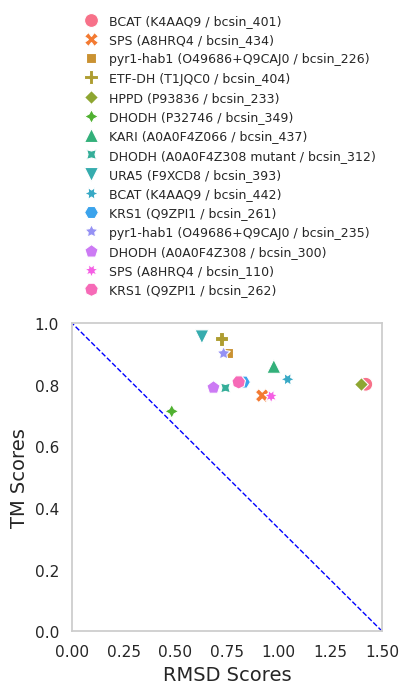

In [159]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style of seaborn
sns.set(style="whitegrid")

# Create a scatter plot
plt.figure(figsize=(4, 4))
sns.scatterplot(data=df, x='RMSD', y='TMscore', hue='out_name', style='out_name', s=100)

# Add a trend line
#sns.regplot(data=df, x='RMSD', y='TMscore', scatter=False, color='red', ci=None)
plt.plot([1.5, 0], [0, 1], color='blue', linestyle='--', linewidth=1)  # Adjust coordinates as needed


# Add labels and title
#plt.title('RMSD vs TMscore for Protein Folding', fontsize=16)
plt.xlabel('RMSD Scores', fontsize=14)
plt.ylabel('TM Scores', fontsize=14)

#set X and Y-axis min max
plt.xlim(0, 1.5)  # Set the x-axis limits (adjust as needed)
plt.ylim(0, 1)  # Set the y-axis limits (adjust as needed)

# add legend
plt.legend(
    bbox_to_anchor=(0.5, 1.05), 
    loc='lower center', 
    ncol=1, 
    fontsize='9',  # Change the font size to make the legend smaller
    handletextpad=0.5,  # Space between legend handle and text
    labelspacing=0.5,    # Space between legend entries
    frameon=False        # Optional: remove the legend frame
)
plt.grid()

# Show the plot
plt.show()

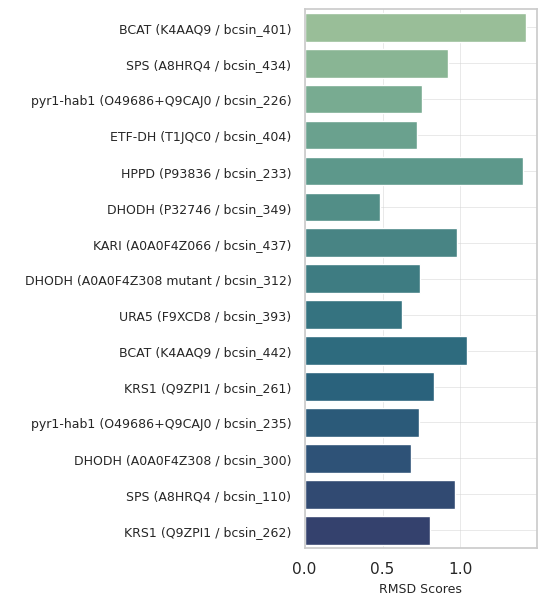

In [147]:
# Create a horizontal bar plot
plt.figure(figsize=(3, 7))  # Increase figure size for better visibility
sns.barplot(y='out_name', x='RMSD', hue="out_name", data=df, palette="crest", orient='h')

# Add labels and title
#plt.title('Bar Plot of RMSD Scores by Protein Target', fontsize=9)
plt.xlabel('RMSD Scores', fontsize=9)
plt.ylabel(' ', fontsize=6)
plt.yticks(fontsize=9)  # Adjust the fontsize as needed
plt.grid(color='lightgrey', linestyle='-', linewidth=0.5, alpha=0.7)  # Adjust alpha for transparency

# Show the plot
plt.show()